<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [OData v2/v4 Reader](https://github.com/Query-farm/vgi-odata)

Read OData v2/v4 REST services from SQL, with $filter pushdown, automatic paging and metadata discovery.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-odata/blob/main/notebooks/02_a_status_flag_changes_the_population.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-odata/blob/main/notebooks/README.md)

## A status flag changes the population

Does excluding discontinued products remove only empty stock rows? Select Northwind v4 from the worker's public-service registry, discover its Products entity set, inspect the declared types, and read twenty products in stable key order. Then change one local inclusion rule while keeping the returned source rows fixed.

Northwind is **provider-authored sample data**, not a real business inventory. The default uses complete, unchanged public HTTP responses captured on **2026-11-15 UTC**. The real native worker parses them through a strict loopback replay; `DATA_MODE="live"` explicitly reads the same bounded public endpoints with no fallback.

### Choose the population rule

`INCLUDE_DISCONTINUED` selects whether the local summary includes rows marked discontinued. It does not change the API request, source data or unit prices. Keep replay mode for the controlled experiment; a live service may change independently. Restart and run all after editing.

In [1]:
DATA_MODE = "replay"
INCLUDE_DISCONTINUED = True  # Experiment: False

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.49":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("odata")
import hashlib
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import MaxNLocator

theme()
session = connect(globals())
connection = session.connection

from public_odata import PublicService

if type(INCLUDE_DISCONTINUED) is not bool:
    raise ValueError("INCLUDE_DISCONTINUED must be True or False")
if DATA_MODE not in ("replay", "live"):
    raise ValueError("DATA_MODE must be replay or live")

### Connect and select a service with the right protocol

The published native **v0.4.0** worker runs through `github-auto`; the extension downloads and verifies its platform archive. Its built-in service registry is an offline convenience list, not a health check. Filter by protocol and choose the named v4 sample before passing its URL to the read functions. The same OData reader accepts services beyond this short registry.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL json;
LOAD json;
ATTACH 'odata' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-odata@v0.4.0');

,Success


In [5]:
%%sql registry <<
SELECT name,service_url,odata_version,description
FROM odata.main.odata_public_services ORDER BY odata_version,name;

In [6]:
display(registry)
selected_service = registry.loc[registry.name.eq("Northwind V4") & registry.odata_version.eq("v4")]
assert len(selected_service) == 1
official_url = selected_service.iloc[0].service_url
source = PublicService(DATA_MODE, official_url)
SERVICE_URL = source.url
prose(
    f"The registry contains **{len(registry)} entries**, including **{int(registry.odata_version.eq('v4').sum())} v4 services**. This example selects **{selected_service.iloc[0]['name']}** at `{official_url}`. Replay serves that service's recorded responses locally; live uses the selected URL directly. Registry membership alone says nothing about current availability."
)

,name,service_url,odata_version,description
0,Northwind V2,https://services.odata.org/V2/Northwind/Northw...,v2,The Northwind sales sample as OData v2 (d.resu...
1,Northwind V3,https://services.odata.org/V3/Northwind/Northw...,v3,The Northwind sales sample exposed as OData v3.
2,Northwind V4,https://services.odata.org/V4/Northwind/Northw...,v4,"The classic Northwind sales sample (Customers,..."
3,OData v4 Sample,https://services.odata.org/V4/OData/OData.svc,v4,The OData.org OData v4 sample service (Product...
4,TripPin,https://services.odata.org/V4/TripPinService,v4,Microsoft's canonical OData v4 reference servi...
5,TripPin RESTier,https://services.odata.org/TripPinRESTierService,v4,Read/write OData v4 TripPin variant hosted by ...


The registry contains **6 entries**, including **4 v4 services**. This example selects **Northwind V4** at `https://services.odata.org/V4/Northwind/Northwind.svc`. Replay serves that service's recorded responses locally; live uses the selected URL directly. Registry membership alone says nothing about current availability.

### Inspect the contract before casting the response

Discover entity sets and EDM property types once, then read **Products** with `$orderby=ProductID`, `$top=20`, and a worker retention cap of 20. The cap bounds this sample; it is not the full Northwind catalog. Entity JSON stays raw until SQL casts each field. ProductID is a key, UnitPrice a per-product unit price, UnitsInStock a unit count and Discontinued a Boolean: numeric types alone do not make measures interchangeable.

In [7]:
%%sql
CREATE TABLE entity_sets AS SELECT * FROM odata.main.odata_entity_sets('{{ SERVICE_URL }}');
CREATE TABLE metadata AS SELECT * FROM odata.main.odata_metadata('{{ SERVICE_URL }}');
CREATE TABLE raw_products AS SELECT * FROM odata.main.odata_query('{{ SERVICE_URL }}','Products',orderby:='ProductID',top:='20',max_rows:=20);
CREATE TABLE products AS SELECT seq,
 try_cast(json_extract_string(entity,'$.ProductID') AS INTEGER) AS product_id,
 json_extract_string(entity,'$.ProductName') AS product_name,
 try_cast(json_extract_string(entity,'$.UnitPrice') AS DOUBLE) AS unit_price,
 try_cast(json_extract_string(entity,'$.UnitsInStock') AS INTEGER) AS stock_units,
 try_cast(json_extract_string(entity,'$.Discontinued') AS BOOLEAN) AS discontinued
FROM raw_products;
CREATE TABLE selected_products AS SELECT * FROM products WHERE {{ INCLUDE_DISCONTINUED }} OR discontinued=false;

,Count


In [8]:
%%sql declarations <<
SELECT property,type AS edm_type FROM metadata WHERE entity_type='Product'
AND property IN ('ProductID','ProductName','UnitPrice','UnitsInStock','Discontinued') ORDER BY property;

In [9]:
display(declarations)
assert connection.execute("SELECT count(*) FROM entity_sets WHERE name='Products'").fetchone()[0] == 1
assert dict(zip(declarations.property, declarations.edm_type, strict=True)) == {
    "ProductID": "Edm.Int32",
    "ProductName": "Edm.String",
    "UnitPrice": "Edm.Decimal",
    "UnitsInStock": "Edm.Int16",
    "Discontinued": "Edm.Boolean",
}
source_fingerprint = hashlib.sha256(
    connection.execute("SELECT * FROM raw_products ORDER BY seq").df().to_json(orient="records").encode()
).hexdigest()
retrieved_at = datetime.now(UTC).isoformat()
prose(
    f"The service exposes **Products** and declares the five projected fields with distinct roles. Materialized source fingerprint: `{source_fingerprint}`. Source mode **{DATA_MODE.upper()}**, retrieval completed **{retrieved_at}**; registry, metadata and entities are separate reads, not an atomic snapshot. The responses carry no inventory observation timestamp."
)
chart_source = f"Northwind provider-authored sample data · {DATA_MODE.upper()} · first20 ProductID-ordered rows\nNative OData v0.4.0 · demonstration units, not observed enterprise stock"

,property,edm_type
0,Discontinued,Edm.Boolean
1,ProductID,Edm.Int32
2,ProductName,Edm.String
3,UnitPrice,Edm.Decimal
4,UnitsInStock,Edm.Int16


The service exposes **Products** and declares the five projected fields with distinct roles. Materialized source fingerprint: `b6b4f6103c484a646bc076f79940b921cb0c32f19f240c8148f9706aad73af7a`. Source mode **REPLAY**, retrieval completed **2026-11-15T01:17:58.428015+00:00**; registry, metadata and entities are separate reads, not an atomic snapshot. The responses carry no inventory observation timestamp.

### Retain the status groups before filtering

First show both status groups in the fixed source sample. Keep product counts and stock-unit sums on separate axes. A discontinued flag is not a statement that stock is zero. Missing stock remains NULL and is counted separately; it is not silently replaced by zero.

In [10]:
%%sql status <<
SELECT CASE WHEN discontinued THEN 'Discontinued' WHEN discontinued=false THEN 'Not discontinued' ELSE 'Unknown status' END AS status,
count(*) AS products,count(stock_units) AS known_stock_products,sum(stock_units) AS stock_units,
count(*) FILTER(WHERE stock_units=0) AS zero_stock_products
FROM products GROUP BY discontinued ORDER BY discontinued NULLS LAST;

In [11]:
display(status)
discontinued = status.loc[status.status.eq("Discontinued")]
prose(
    f"The fixed sample contains **{int(status.products.sum())} products**. **{int(discontinued.products.sum())}** are marked discontinued, but their known stock still totals **{discontinued.stock_units.sum():g} units**. Zero stock and discontinued status describe different properties; the source flag does not erase the returned inventory quantity."
)

,status,products,known_stock_products,stock_units,zero_stock_products
0,Not discontinued,17,17,636.0,0
1,Discontinued,3,3,29.0,2


The fixed sample contains **20 products**. **3** are marked discontinued, but their known stock still totals **29 units**. Zero stock and discontinued status describe different properties; the source flag does not erase the returned inventory quantity.

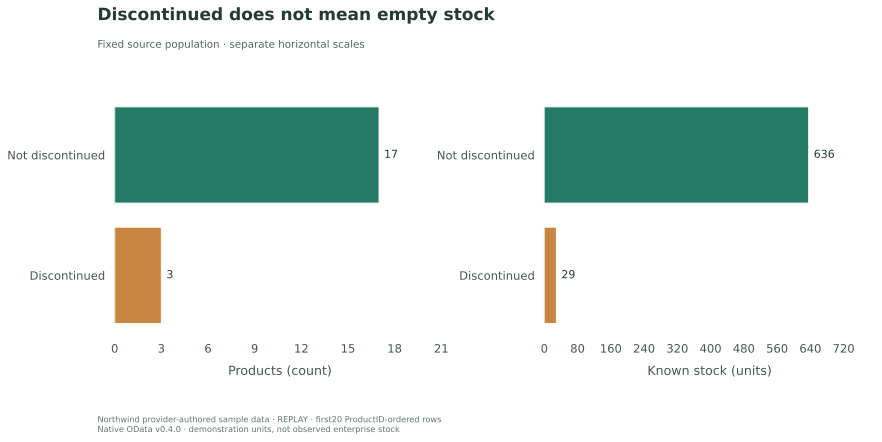

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, field, label in zip(
    axes, ["products", "stock_units"], ["Products (count)", "Known stock (units)"], strict=True
):
    bars = ax.barh(status.status, status[field], color=["#237B65", "#C78541"])
    ax.bar_label(bars, padding=5, fmt="%.0f")
    ax.set_xlim(0, max(1, float(status[field].max())) * 1.25)
    ax.set_xlabel(label)
    ax.invert_yaxis()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
finish(
    fig,
    "Discontinued does not mean empty stock",
    "Fixed source population · separate horizontal scales",
    chart_source,
    name="northwind-status",
)

### Compare the selected rows with the same source sample

The experiment removes discontinued rows locally. Every retained row keeps the same key, name, price and stock. The table lists all source rows so excluded products remain visible. The chart pairs stock counts by status; it does not add prices to quantities, estimate a reorder target or extrapolate to products beyond these twenty IDs.

In [13]:
%%sql selected <<
SELECT p.*,s.product_id IS NOT NULL AS included FROM products p LEFT JOIN selected_products s USING(product_id) ORDER BY product_id;

In [14]:
display(selected)
prose(
    f"With discontinued inclusion **{INCLUDE_DISCONTINUED}**, **{int(selected.included.sum())}/{len(selected)} source products** remain. Their known stock totals **{selected.loc[selected.included, 'stock_units'].sum():g} units**, compared with **{selected.stock_units.sum():g}** in the fixed source sample. Any missing measurements stay visible in the table. These totals answer two population questions; they do not revise the source rows."
)

,seq,product_id,product_name,unit_price,stock_units,discontinued,included
0,0,1,Chai,18.00,39,False,True
1,1,2,Chang,19.00,17,False,True
2,2,3,Aniseed Syrup,10.00,13,False,True
3,3,4,Chef Anton's Cajun Seasoning,22.00,53,False,True
4,4,5,Chef Anton's Gumbo Mix,21.35,0,True,True
5,5,6,Grandma's Boysenberry Spread,25.00,120,False,True
6,6,7,Uncle Bob's Organic Dried Pears,30.00,15,False,True
7,7,8,Northwoods Cranberry Sauce,40.00,6,False,True
8,8,9,Mishi Kobe Niku,97.00,29,True,True
9,9,10,Ikura,31.00,31,False,True


With discontinued inclusion **True**, **20/20 source products** remain. Their known stock totals **665 units**, compared with **665** in the fixed source sample. Any missing measurements stay visible in the table. These totals answer two population questions; they do not revise the source rows.

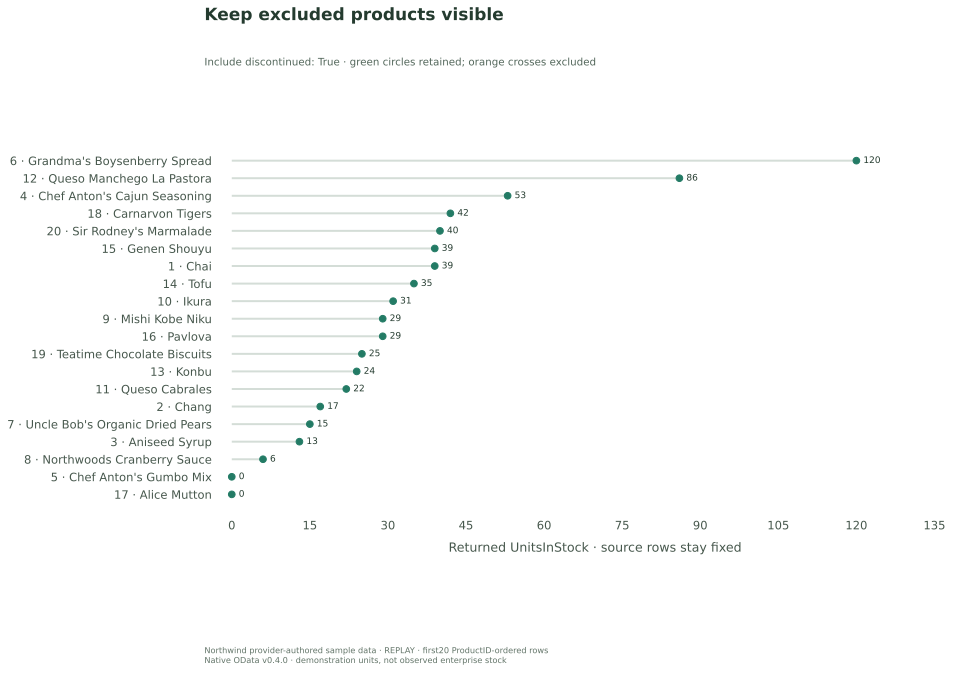

In [15]:
plot = selected.sort_values("stock_units", ascending=False)
fig, ax = plt.subplots(figsize=(11.8, 10))
y = np.arange(len(plot))
ax.hlines(y, 0, plot.stock_units, color="#D4DDD7", linewidth=2)
for i, row in enumerate(plot.itertuples()):
    ax.scatter(
        row.stock_units,
        i,
        color="#237B65" if row.included else "#C78541",
        marker="o" if row.included else "x",
        s=45,
        zorder=3,
    )
    ax.annotate(
        str(row.stock_units),
        (row.stock_units, i),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )
ax.set_yticks(y, [f"{row.product_id} · {row.product_name}" for row in plot.itertuples()])
ax.invert_yaxis()
ax.set_xlim(-2, max(1, float(plot.stock_units.max())) * 1.18)
ax.set_xlabel("Returned UnitsInStock · source rows stay fixed")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
finish(
    fig,
    "Keep excluded products visible",
    f"Include discontinued: {INCLUDE_DISCONTINUED} · green circles retained; orange crosses excluded",
    chart_source,
    name=f"northwind-selected-{INCLUDE_DISCONTINUED}",
)

In [16]:
%%sql checks <<
SELECT 'Bounded nonempty source sample' AS check_name,count(*) BETWEEN 1 AND 20 AS passed FROM products
UNION ALL SELECT 'Unique nonmissing product keys',count(*)=count(DISTINCT product_id) AND count(product_id)=count(*) FROM products
UNION ALL SELECT 'Stable ascending key order',bool_and(product_id>previous_id OR previous_id IS NULL) FROM (SELECT product_id,lag(product_id) OVER(ORDER BY seq) AS previous_id FROM products)
UNION ALL SELECT 'Nonnegative observed stock and price',bool_and((stock_units IS NULL OR stock_units>=0) AND (unit_price IS NULL OR unit_price>=0)) FROM products
UNION ALL SELECT 'All sample status flags known',bool_and(discontinued IS NOT NULL) FROM products
UNION ALL SELECT 'Selection equals requested predicate',count(*)=0 FROM ((SELECT * FROM selected_products EXCEPT ALL SELECT * FROM products WHERE {{ INCLUDE_DISCONTINUED }} OR NOT discontinued) UNION ALL (SELECT * FROM products WHERE {{ INCLUDE_DISCONTINUED }} OR NOT discontinued EXCEPT ALL SELECT * FROM selected_products))
UNION ALL SELECT 'Selected values are unchanged source rows',count(*)=0 FROM (SELECT * FROM selected_products EXCEPT ALL SELECT * FROM products)
UNION ALL SELECT 'Selected count cannot grow',(SELECT count(*) FROM selected_products)<=(SELECT count(*) FROM products);

In [17]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
assert int(status.products.sum()) == len(selected)
if source.server:
    assert len(source.requests) == 3, source.requests
prose(
    f"**{len(checks)} SQL invariants** and status-population reconciliation passed. Replay validates exactly three service requests; live makes the explicit public reads without a replay fallback."
)

,check_name,passed
0,Bounded nonempty source sample,True
1,Unique nonmissing product keys,True
2,Stable ascending key order,True
3,Nonnegative observed stock and price,True
4,All sample status flags known,True
5,Selection equals requested predicate,True
6,Selected values are unchanged source rows,True
7,Selected count cannot grow,True


**8 SQL invariants** and status-population reconciliation passed. Replay validates exactly three service requests; live makes the explicit public reads without a replay fallback.

### Experiment: exclude discontinued rows

Change only **INCLUDE_DISCONTINUED=True → False**. Predict which orange crosses appear and subtract the discontinued group's known stock from the fixed total. The registry, service URL, three requests, source fingerprint, schema and status chart must stay unchanged; only local membership and its totals change. Do not interpret the resulting population as a complete catalog or an inventory recommendation.

Source: [OData.org Northwind reference service](https://services.odata.org/V4/Northwind/Northwind.svc). Original bytes, request URLs, UTC capture times and SHA-256 hashes are retained in `recordings/provenance.json`. The first notebook separately demonstrates paging with entirely invented fixture data.

In [18]:
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-odata](https://github.com/Query-farm/vgi-odata)